# Caso UTEC · Re-identificación de personas no supervisada con AIS y AFEM

**Método:** Wang et al. (2024), *Unsupervised person re-identification based on adaptive information supplementation and foreground enhancement*, IET Image Processing 18, 4680–4694.
**Datos:** `data/training.h5`, `data/validation.h5`, `data/testing.h5` (Market-1501, Laboratorio 3).

**El problema.** A partir de una imagen de consulta (*query*), el modelo genera un vector y ordena una galería (*gallery*) por similitud para encontrar a la misma persona captada por **otras cámaras**, **sin usar etiquetas de identidad en el entrenamiento**. El caso de uso son las **queries de baja resolución** (32 × 16 píxeles, cámara lejana o de mala calidad) contra una gallery en resolución original.

**Uso de cada archivo**

| Archivo | Uso | ¿Tiene etiquetas de identidad? |
|---|---|---|
| `training.h5` (11 043 imágenes) | entrenar | **no** |
| `validation.h5` (100 queries + 1 793 gallery) | medir con las etiquetas correctas y **elegir** la configuración, la época y el flip TTA | sí, solo para medir |
| `testing.h5` (3 368 queries + 19 732 gallery) | **predecir** y calcular las métricas finales | sí, solo para medir; nunca para elegir |

**Contenido**

| Sección | Tema |
|---|---|
| 1–2 | datos y preprocesamiento |
| 3 | el método del paper y cómo actúa cada componente |
| 4 | **qué se valida y cómo se miden las métricas**, con un ejemplo paso a paso |
| 5–6 | entrenamiento y validación (métrica del caso de uso) |
| 7 | **aporte de cada componente** (ablación con intervalos de confianza), **mejoras probadas** para el caso y **variación entre semillas** |
| 8 | **qué hacen AFEM y AIS por dentro** |
| 9–12 | test, aciertos y fallos, patrones de error, predicciones |
| 13 | conclusiones y limitaciones |

**Cómo ejecutar** (scripts en `scripts/`):
```bash
conda activate GPU_env
cd Caso_UTEC/scripts
powershell -ExecutionPolicy Bypass -File run_cola.ps1   # entrena, valida, elige, entrena el final, réplicas con otras semillas, predice y diagnostica (~8 h)
```

### Celda de configuración (la siguiente)

| Nombre | Qué es |
|---|---|
| `sys.path.insert(0, "scripts")` | permite importar los módulos del caso: `reid_caso` (datos, modelo, pérdidas, clustering, entrenamiento y métricas) y `run_caso` (las configuraciones del experimento) |
| `FIG` | carpeta donde se guardan las figuras (`presentacion/figuras`) |
| `mean`, `std` | media y desviación por canal RGB de ImageNet. Las imágenes se normalizan con ellas porque el backbone ResNet-50 viene preentrenado en ImageNet; aquí se usan para "des-normalizar" al dibujar |
| `EXPS` | las configuraciones entrenadas (ver sección 5): seis para la ablación del paper y tres mejoras para el caso |
| `COL` | color de cada configuración en los gráficos |
| `ENTRENAR` | `False`: carga los resultados ya calculados de `presentacion/`. `True`: vuelve a ejecutar todo con `run_cola.ps1` (~8 h en GPU) |
| `R` | diccionario con todos los resultados (`presentacion/resultados/resultados_caso.json`): configuración, pérdidas y clusters por época, validación cada 5 épocas, selección y test |
| `D` | métricas por query para los intervalos de confianza y diagnósticos de AFEM y AIS (`diagnostico.npz`) |

In [1]:
import os, sys, json, inspect, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import h5py
sys.path.insert(0, os.path.abspath("scripts"))
import reid_caso as rc
import run_caso
import aportes
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 200)
FIG = os.path.join("presentacion", "figuras")
os.makedirs(FIG, exist_ok=True)
mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
EXPS = ["base", "base_afem", "ais_lg", "ais_lg_lp", "completo", "completo_sin_aumento",
        "ais_lg_lp_consistencia", "ais_lg_lp_p07", "ais_lg_lp_f35"]
MEJORAS = ["ais_lg_lp_consistencia", "ais_lg_lp_p07", "ais_lg_lp_f35"]
COL = {"base": "#9AA3B2", "base_afem": "#4C9BE8", "ais_lg": "#D98E1F", "ais_lg_lp": "#C2414B", "completo": "#0E9384",
       "completo_sin_aumento": "#16213E", "final": "#7A5CC4",
       "ais_lg_lp_consistencia": "#E377C2", "ais_lg_lp_p07": "#8C564B", "ais_lg_lp_f35": "#BCBD22"}

ENTRENAR = False
if ENTRENAR:
    subprocess.run(["powershell", "-ExecutionPolicy", "Bypass", "-File", os.path.join("scripts", "run_cola.ps1")], check=True)
R = json.load(open(rc.RESULTS_PATH, encoding="utf-8"))
D = np.load(os.path.join("presentacion", "resultados", "diagnostico.npz"))
DIAG = json.load(open(os.path.join("presentacion", "resultados", "diagnostico.json"), encoding="utf-8"))
SEL = R["seleccion"]
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU", "· PyTorch", torch.__version__)
print("Configuraciones completas:", {k: R[k]["done"] for k in EXPS + ["final"]})
print(f"Configuración elegida con validación: {SEL['configuracion']} · {SEL['epocas']} épocas · flip TTA = {SEL['opcion_elegida']['flip_tta']}")

GPU: NVIDIA GeForce RTX 5070 Ti · PyTorch 2.11.0+cu130
Configuraciones completas: {'base': True, 'base_afem': True, 'ais_lg': True, 'ais_lg_lp': True, 'completo': True, 'completo_sin_aumento': True, 'ais_lg_lp_consistencia': True, 'ais_lg_lp_p07': True, 'ais_lg_lp_f35': True, 'final': True}
Configuración elegida con validación: ais_lg_lp · 20 épocas · flip TTA = True


## 1. Carga de datos y particiones

`rc.load_split` lee cada HDF5 una sola vez y deja las imágenes como tensores `uint8` de forma (N, 3, 128, 64) en RGB, junto con la cámara, el `image_id` y, en validación y test, la identidad (`person_id`).

In [2]:
train = rc.load_split("training")["train"]
val = rc.load_split("validation")
test = rc.load_split("testing")
filas = [{"Archivo": "training.h5", "Parte": "—", "Imágenes": len(train["cams"]), "Personas": "sin etiquetas",
          "Cámaras": len(set(train["cams"])), "Queries baja res.": "—"}]
for nombre, s in (("validation.h5", val), ("testing.h5", test)):
    for parte in ("query", "gallery"):
        d = s[parte]
        filas.append({"Archivo": nombre, "Parte": parte, "Imágenes": len(d["pids"]), "Personas": len(set(d["pids"][d["pids"] > 0])),
                      "Cámaras": len(set(d["cams"])), "Queries baja res.": "32×16" if "images_low" in d else "—"})
pd.DataFrame(filas)

,Archivo,Parte,Imágenes,Personas,Cámaras,Queries baja res.
0,training.h5,—,11043,sin etiquetas,6,—
1,validation.h5,query,100,100,6,32×16
2,validation.h5,gallery,1793,100,6,—
3,testing.h5,query,3368,750,6,32×16
4,testing.h5,gallery,19732,750,6,—


In [3]:
with h5py.File(os.path.join(rc.DATA_DIR, "training.h5"), "r") as f:
    print("training.h5 · usage:", f.attrs["usage"])
    print("training.h5 · final_training:", f.attrs["final_training"])
with h5py.File(os.path.join(rc.DATA_DIR, "testing.h5"), "r") as f:
    print("testing.h5 · low_resolution:", f.attrs["low_resolution"])

training.h5 · usage: Unlabelled development training. Identity labels are not included.
training.h5 · final_training: After choosing the configuration, combine these images with validation/query/images and validation/gallery/images, without using identity labels.
testing.h5 · low_resolution: query/images_low_resolution matches query/images in the same order. Width and height reduced by four using bicubic interpolation.


- Las 100 personas de validación no están en `training.h5`, y las 750 de test son distintas de ambas: **siempre se mide con personas que el modelo nunca vio**.
- En la gallery de test hay imágenes basura (ID −1), que se excluyen al medir como en el protocolo estándar, y distractores (ID 0), que cuentan como errores si aparecen arriba.
- El atributo `final_training` indica que, una vez elegida la configuración, el modelo final puede entrenarse sumando las imágenes de validación **sin sus etiquetas**.

## 2. Preprocesamiento y transformaciones

| Etapa | Transformación | Motivo |
|---|---|---|
| Todas | 128 × 64 → 384 × 128 (bicúbica) y normalización ImageNet | tamaño de entrada del paper; el backbone está preentrenado en ImageNet |
| Entrenamiento (paper) | flip horizontal p = 0.5, pad 10 + recorte, random erasing p = 0.5 | robustez a pose, encuadre y oclusiones |
| Entrenamiento (**adaptación**) | **aumento de resolución**: con p = 0.5, reducir la imagen 2–4× (bicúbica con antialias) y volver a subirla | que el modelo aprenda con imágenes como las queries del caso |
| Clustering, validación y test | solo redimensionar y normalizar | medir sin aleatoriedad |

El enunciado lo permite expresamente: *"Si trabaja con imágenes de distinta resolución, podrán generar esas versiones a partir de las imágenes de entrenamiento"*.

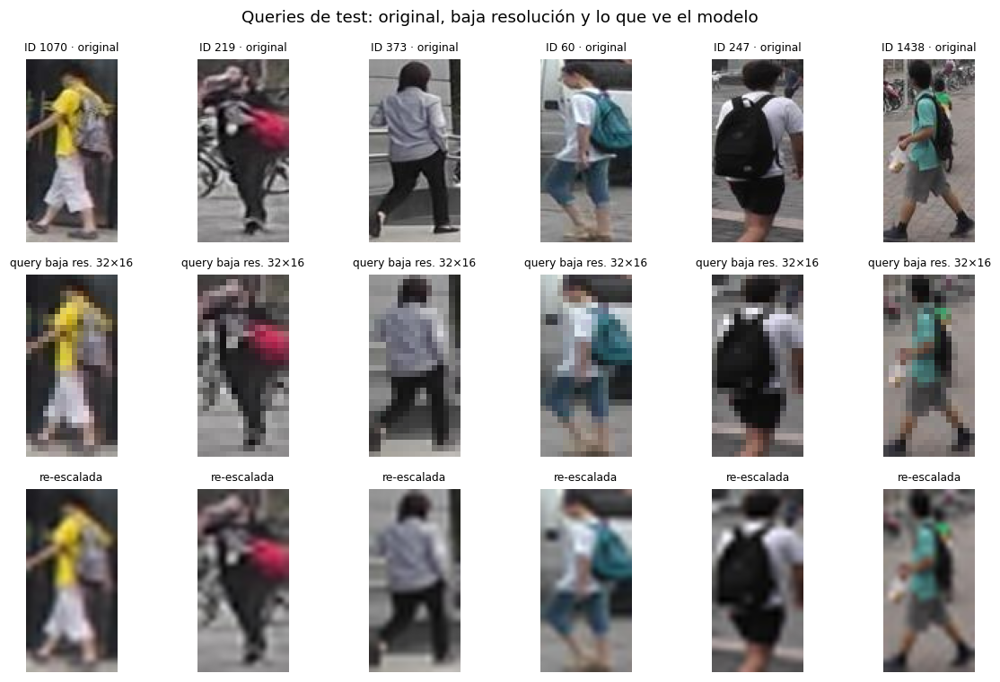

In [4]:
q = test["query"]
sel = np.random.RandomState(0).choice(len(q["pids"]), 6, replace=False)
up = rc.to_input(q["images_low"][sel], 128, 64).cpu()
fig, ax = plt.subplots(3, 6, figsize=(11, 7))
for k, i in enumerate(sel):
    ax[0, k].imshow(q["images"][i].permute(1, 2, 0).numpy()); ax[0, k].set_title(f"ID {q['pids'][i]} · original", fontsize=8)
    ax[1, k].imshow(q["images_low"][i].permute(1, 2, 0).numpy()); ax[1, k].set_title("query baja res. 32×16", fontsize=8)
    ax[2, k].imshow(np.clip(up[k].permute(1, 2, 0).numpy() * std + mean, 0, 1)); ax[2, k].set_title("re-escalada", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Queries de test: original, baja resolución y lo que ve el modelo"); plt.tight_layout()
plt.savefig(os.path.join(FIG, "queries_baja_resolucion.png"), dpi=130); plt.show()

La degradación simulada (factor 4) difiere de la provista en 0.23 niveles de gris en promedio (de 255): el aumento reproduce el proceso con que se generaron las queries del caso.


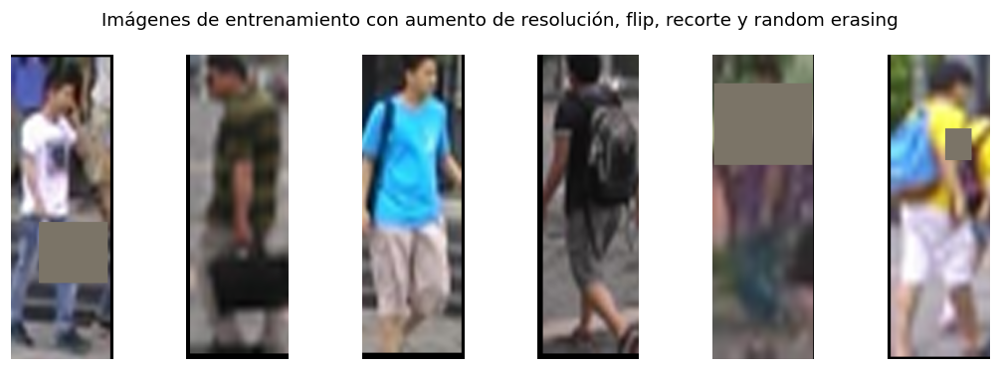

In [5]:
x = q["images"][:512].float() / 255
sim = rc.degrade(x, 4.0).numpy()
real = F.interpolate(q["images_low"][:512].float() / 255, size=(128, 64), mode="bicubic", align_corners=False).clamp(0, 1).numpy()
print(f"La degradación simulada (factor 4) difiere de la provista en {np.abs(sim - real).mean() * 255:.2f} niveles de gris "
      "en promedio (de 255): el aumento reproduce el proceso con que se generaron las queries del caso.")
torch.manual_seed(1)
aug = rc.train_augment(train["images"][:6].cuda(), dict(rc.PAPER, res_aug_p=1.0)).cpu()
fig, ax = plt.subplots(1, 6, figsize=(10, 3.4))
for k in range(6):
    ax[k].imshow(np.clip(aug[k].permute(1, 2, 0).numpy() * std + mean, 0, 1)); ax[k].axis("off")
plt.suptitle("Imágenes de entrenamiento con aumento de resolución, flip, recorte y random erasing"); plt.tight_layout(); plt.show()

## 3. El método del paper y cómo actúa cada componente

### 3.1 Idea general

Sin etiquetas, el método alterna dos pasos en cada época:
1. **Pseudo-etiquetas.** Calcula el vector de cada imagen de `training.h5` y las agrupa con **DBSCAN** sobre la **distancia de Jaccard k-recíproca**. Cada grupo (cluster) se trata como si fuera una persona.
2. **Aprendizaje de representación.** Entrena la red para que las imágenes de un mismo cluster queden cerca y las de clusters distintos lejos.

Si la red mejora, los clusters se parecen más a personas reales, y viceversa. El paper agrega dos piezas a este ciclo: **AFEM** y **AIS**.

### 3.2 AFEM (Adaptive Foreground Enhancement Module) · ec. 1–4

- **Objetivo:** reforzar al peatón (primer plano) y atenuar el fondo **antes del clustering**, para que las pseudo-etiquetas no se formen por fondos parecidos.
- **Cómo:** sobre el mapa de features de la ResNet (2048 canales × 24 × 8):
  1. Group Normalization en 16 grupos.
  2. Un peso por canal `W_γ = softmax(γ)`.
  3. `r = Sigmoid(W_γ · GN(X))`.
  4. Compuerta T = 0.5: donde r > 0.5 la activación se conserva entera (máscara 1); en el resto se multiplica por r (≈ 0.5).
- **Dónde actúa:** dentro de la red, en el clustering, el entrenamiento **y el test**.

### 3.3 AIS (Adaptive Information Supplementation) · ec. 5–11

- **Objetivo:** aprovechar el detalle de tres franjas del cuerpo (cabeza, torso, piernas) **sin creerle a las franjas poco confiables** (ocluidas o con fondo).
- **Cómo:**
  1. **Puntaje S por franja (ec. 5).** Para cada imagen se buscan sus 30 vecinos más cercanos usando el vector global y los 30 vecinos usando cada franja. Si la franja "ve a las mismas personas" que el vector global, S es alto (confiable); si no, S es bajo.
  2. **Lg (ec. 9–11).** La etiqueta del vector global deja de ser "100 % el cluster c" y se mezcla con lo que predicen las franjas, ponderadas por softmax(S) (β = 0.5).
  3. **Lp (ec. 8).** Cada franja aprende la etiqueta con peso S; si S es bajo, se le pide en cambio no estar segura (KL contra la distribución uniforme).
- **Dónde actúa:** **solo durante el entrenamiento**, como ponderación de las pérdidas. En test se usa únicamente el vector global; AIS ya dejó su efecto en los pesos de la red. Por eso su aporte **solo se puede medir entrenando con y sin AIS** (ablación).

### 3.4 Pérdida total (ec. 14)

**L = Lp + Lg + Ltriplet + 0.5 · Lcam**
- **Ltriplet** (softmax-triplet): acerca al positivo más difícil y aleja al negativo más difícil del batch.
- **Lcam** (contraste entre cámaras con proxies por cámara, τ = 0.07): acerca las vistas de un mismo cluster en cámaras distintas.

### 3.5 Implementación (`scripts/reid_caso.py`)

| Componente | Función |
|---|---|
| ResNet-50 (último stride 1), ramas global y local, BNNeck | `ReIDModel` |
| AFEM | `AFEM` |
| Puntaje S de AIS | `ais_scores` |
| Lp, Lg, triplet, Lcam | `train_experiment`, `soft_triplet`, `cam_loss`, `build_proxies` |
| Jaccard k-recíproca + DBSCAN | `jaccard_sparse`, `cluster` |
| Métricas (coseno, mAP, CMC) | `evaluate`, `evaluate_per_query` |

**Adaptaciones al caso** (la propuesta central se conserva):
1. **Aumento de resolución** (sección 2).
2. **AFEM sin weight decay** en γ y β. Con el weight decay del paper, γ colapsa a 0 en ~15 épocas y AFEM queda como X · 0.5.
3. **Época elegida con validación.**
4. **Modelo final** entrenado con train + imágenes de validación sin etiquetas.

In [6]:
print(inspect.getsource(rc.AFEM))
print(inspect.getsource(rc.ais_scores))

class AFEM(nn.Module):
    """Adaptive Foreground Enhancement Module (ec. 1-4)."""

    def __init__(self, channels=2048, groups=16, threshold=0.5, eps=1e-10):
        super().__init__()
        self.gn = nn.GroupNorm(groups, channels, eps=eps)
        self.threshold = threshold

    def forward(self, x):
        x = x.float()
        gn = self.gn(x)                                                        # ec. 1
        w_gamma = F.softmax(self.gn.weight, dim=0).view(1, -1, 1, 1)           # ec. 2
        reweights = torch.sigmoid(gn * w_gamma)
        w1 = torch.where(reweights > self.threshold, torch.ones_like(reweights), reweights)  # ec. 3
        return w1 * x                                                          # ec. 4

@torch.no_grad()
def ais_scores(g, parts, k, chunk=512):
    """Puntaje S (ec. 5): coseno medio entre los K vecinos de la franja n y los K vecinos del global."""
    gn = F.normalize(g.float(), dim=1).half()
    rank_g = topk_neighbors(gn, k)
    S = torch.zer

## 4. ¿Qué se valida y cómo se mide?

### 4.1 Qué se quiere validar

El modelo no clasifica personas: convierte cada imagen en un vector de 2048 números. Para buscar a alguien se compara el vector de la query con el de cada imagen de la gallery (**similitud coseno** entre vectores normalizados L2) y se **ordena** la gallery.

**Validar es comprobar que ese ranking pone arriba a la misma persona vista desde otras cámaras.** Es necesario porque el entrenamiento nunca vio etiquetas: el modelo aprendió con pseudo-etiquetas que él mismo inventó, y solo con las etiquetas reales de `validation.h5` sabemos si esas pseudo-etiquetas se convirtieron en identidades reales. Se mide en las dos condiciones del enunciado, con el **mismo modelo**:

| Condición | Query | Gallery | Rol |
|---|---|---|---|
| Imágenes originales | 128 × 64 | original | referencia |
| **Queries de baja resolución** | **32 × 16** | **original** | **métrica del caso de uso: con ella se decide** |

**La validación se usa para elegir** (nunca para entrenar):
1. Qué configuración: qué componentes del paper usar.
2. En qué época quedarse: el rendimiento sube y luego baja.
3. Si se promedia la imagen con su versión volteada (flip TTA).

El test no interviene en ninguna de esas decisiones; así su resultado es una estimación honesta.

### 4.2 Las métricas

Para una query, se recorre el ranking de la gallery. Antes se excluyen las imágenes de la **misma persona y misma cámara** (sería trivial encontrarlas) y la basura (ID −1).

| Métrica | Definición | Qué mide |
|---|---|---|
| **Rank-k** (CMC) | % de queries con al menos una foto correcta entre las k primeras | si el operador encuentra a la persona mirando k resultados |
| **AP** (de una query) | promedio, sobre cada foto correcta, de la precisión en su posición (correctas hasta ahí / posición) | si **todas** las fotos correctas quedaron arriba |
| **mAP** | promedio del AP sobre todas las queries | calidad global del ranking |
| **Caída de mAP** | mAP con originales − mAP con baja resolución | robustez a la resolución (pide el enunciado) |

**Ejemplo paso a paso** con una query real de validación y el modelo elegido:

In [7]:
cfg_sel = R[SEL["configuracion"]]["config"]
m_sel = rc.load_model(cfg_sel, R[SEL["configuracion"]]["checkpoint_mejor"])
flip = SEL["opcion_elegida"]["flip_tta"]
vq, vg = val["query"], val["gallery"]
gfeat, _ = rc.extract(m_sel, vg["images"], cfg_sel, flip_tta=flip)
qfeat, _ = rc.extract(m_sel, vq["images_low"], cfg_sel, flip_tta=flip)
aps, firsts = rc.evaluate_per_query(qfeat, gfeat, vq, vg)
qi = int(np.argsort(aps)[len(aps) // 3])          # una query de rendimiento intermedio-bajo, para que haya errores
simil = (F.normalize(qfeat[qi:qi + 1].float(), dim=1) @ F.normalize(gfeat.float(), dim=1).t()).squeeze(0).cpu().numpy()
orden = np.argsort(-simil)
ok_mask = ~((vg["pids"][orden] == vq["pids"][qi]) & (vg["cams"][orden] == vq["cams"][qi]))
orden = orden[ok_mask]                              # se excluyen misma persona + misma cámara
correcta = vg["pids"][orden] == vq["pids"][qi]
n_corr = int(correcta.sum())
filas, aciertos = [], 0
for pos in range(1, len(orden) + 1):
    if correcta[pos - 1]:
        aciertos += 1
    if pos <= 15 or (correcta[pos - 1] and aciertos <= n_corr):
        if pos <= 15 or correcta[pos - 1]:
            filas.append({"posición": pos, "similitud coseno": round(float(simil[orden[pos - 1]]), 3),
                          "ID gallery": int(vg["pids"][orden[pos - 1]]), "cámara": int(vg["cams"][orden[pos - 1]]) + 1,
                          "¿misma persona?": "sí" if correcta[pos - 1] else "no",
                          "precisión en esta posición": round(aciertos / pos, 3) if correcta[pos - 1] else ""})
    if aciertos == n_corr and pos > 15:
        break
tabla_ej = pd.DataFrame(filas)
prec = [r["precisión en esta posición"] for r in filas if r["¿misma persona?"] == "sí"]
print(f"Query ID {vq['pids'][qi]} (cámara {vq['cams'][qi] + 1}), en baja resolución. Fotos correctas en la gallery (otras cámaras): {n_corr}")
print(f"AP = promedio de las precisiones en cada acierto = ({' + '.join(f'{p:.3f}' for p in prec)}) / {n_corr} = {np.mean(prec):.3f}"
      f"   (calculado por el código: {aps[qi]:.3f})")
print(f"Primer acierto en la posición {int(firsts[qi])} → cuenta para Rank-k con k ≥ {int(firsts[qi])}")
tabla_ej

Query ID 792 (cámara 2), en baja resolución. Fotos correctas en la gallery (otras cámaras): 15
AP = promedio de las precisiones en cada acierto = (1.000 + 1.000 + 0.750 + 0.800 + 0.625 + 0.600 + 0.538 + 0.364 + 0.281 + 0.303 + 0.244 + 0.146 + 0.113 + 0.104 + 0.069) / 15 = 0.462   (calculado por el código: 0.463)
Primer acierto en la posición 1 → cuenta para Rank-k con k ≥ 1


,posición,similitud coseno,ID gallery,cámara,¿misma persona?,precisión en esta posición
0,1,0.754,792,3,sí,1.0
1,2,0.723,792,5,sí,1.0
2,3,0.720,307,5,no,
3,4,0.720,792,5,sí,0.75
4,5,0.720,792,3,sí,0.8
5,6,0.711,307,2,no,
6,7,0.707,307,5,no,
7,8,0.702,792,5,sí,0.625
8,9,0.697,307,3,no,
9,10,0.695,792,3,sí,0.6


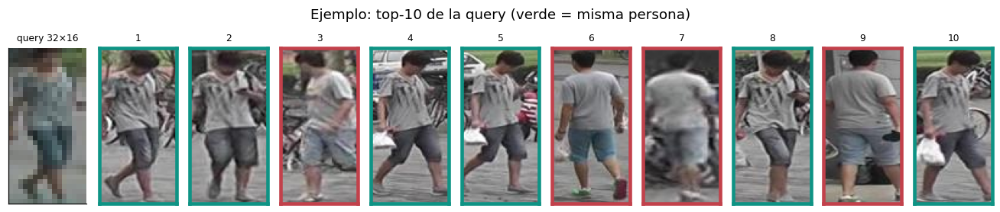

mAP de validación (baja resolución) del modelo elegido = promedio de los AP de las 100 queries = 61.54


In [8]:
fig, ax = plt.subplots(1, 11, figsize=(12, 2.6))
ax[0].imshow(vq["images_low"][qi].permute(1, 2, 0).numpy()); ax[0].set_title("query 32×16", fontsize=8)
for k in range(10):
    j = orden[k]
    ax[k + 1].imshow(vg["images"][j].permute(1, 2, 0).numpy()); ax[k + 1].set_title(f"{k + 1}", fontsize=8)
    for s in ax[k + 1].spines.values():
        s.set_visible(True); s.set_linewidth(3); s.set_color("#0E9384" if correcta[k] else "#C2414B")
for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.suptitle("Ejemplo: top-10 de la query (verde = misma persona)"); plt.tight_layout(); plt.show()
print(f"mAP de validación (baja resolución) del modelo elegido = promedio de los AP de las 100 queries = {np.nanmean(aps) * 100:.2f}")
del m_sel

**Por qué la validación da valores más altos que el test.** La gallery de validación tiene 1 793 imágenes de 100 personas y ningún distractor; la de test, 19 732 imágenes de 750 personas más distractores. Con más candidatos parecidos es más difícil quedar primero. La validación sirve para **comparar configuraciones entre sí**, no para estimar el número de test.

## 5. Entrenamiento

Configuración del paper: 50 épocas × 400 iteraciones, batch de 8 pseudo-identidades × 4 imágenes, Adam (lr 3.5e-4, weight decay 5e-4, ÷10 cada 20 épocas). En cada época:
1. Features de todo el train.
2. Jaccard k-recíproca y DBSCAN (eps 0.5, mínimo 4 imágenes por cluster).
3. Clasificadores iniciados con los centroides de los clusters.
4. Puntajes S de AIS y proxies por cámara.
5. 400 iteraciones.

Cada 5 épocas se mide en validación. Se entrenan nueve configuraciones con `training.h5`:
- **Seis para la ablación del paper**, diseñadas para que cada componente tenga una comparación con y sin él (sección 7.1).
- **Tres mejoras para el caso de uso** sobre AIS con Lg y Lp, que no cambian el método del paper ni las reglas del enunciado (sección 7.2).

Además, la configuración elegida y el base se repiten con otras dos semillas para medir la variación entre entrenamientos (sección 7.3).

In [9]:
pd.DataFrame([{"Configuración": k, "Descripción": run_caso.DESCRIPCION[k], "AFEM": c["afem"], "AIS (Lg)": c["ais"], "Lp": c["lp"],
               "aumento de resolución": f"p={c['res_aug_p']:g} · {c['res_aug_min']:g}–{c['res_aug_max']:g}×" if c["res_aug_p"] > 0 else "no",
               "consistencia": c.get("cons_weight", 0.0)}
              for k, c in run_caso.EXPERIMENTOS.items()]).set_index("Configuración")

,Descripción,AFEM,AIS (Lg),Lp,aumento de resolución,consistencia
Configuración,,,,,,
base,"modelo base: ResNet-50 + CE + triplet + Lcam, ...",False,False,False,p=0.5 · 2–4×,0.0
ais_lg,base + AIS con Lg,False,True,False,p=0.5 · 2–4×,0.0
completo,método completo: AFEM + AIS (Lg + Lp),True,True,True,p=0.5 · 2–4×,0.0
completo_sin_aumento,método completo sin aumento de resolución,True,True,True,no,0.0
base_afem,base + AFEM,True,False,False,p=0.5 · 2–4×,0.0
ais_lg_lp,base + AIS con Lg y Lp,False,True,True,p=0.5 · 2–4×,0.0
ais_lg_lp_consistencia,AIS (Lg + Lp) + pérdida de consistencia entre ...,False,True,True,p=0.5 · 2–4×,1.0
ais_lg_lp_p07,AIS (Lg + Lp) con aumento de resolución p = 0.7,False,True,True,p=0.7 · 2–4×,0.0
ais_lg_lp_f35,AIS (Lg + Lp) con reducción 3–5× en el aumento,False,True,True,p=0.5 · 3–5×,0.0


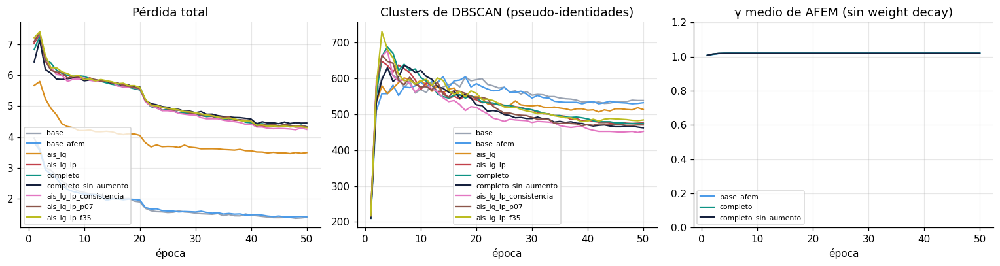

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for n in EXPS:
    e = R[n]["epochs"]
    ep = [x["epoch"] for x in e]
    ax[0].plot(ep, [x["loss"] for x in e], color=COL[n], label=n)
    ax[1].plot(ep, [x["clusters"] for x in e], color=COL[n], label=n)
    if e[0].get("afem_gamma_mean") is not None:
        ax[2].plot(ep, [x["afem_gamma_mean"] for x in e], color=COL[n], label=n)
ax[0].set_title("Pérdida total"); ax[1].set_title("Clusters de DBSCAN (pseudo-identidades)"); ax[2].set_title("γ medio de AFEM (sin weight decay)")
ax[2].set_ylim(0, 1.2)
for a in ax: a.set_xlabel("época"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "entrenamiento.png"), dpi=130); plt.show()

- El número de clusters sube al inicio, cuando el modelo de ImageNet aún no distingue personas y DBSCAN deja muchas imágenes como ruido, y luego se estabiliza en ~450–550. El train tiene 651 personas reales, así que DBSCAN fusiona a algunas.
- Las configuraciones con AIS tienen pérdidas mayores porque suman Lg (con etiqueta suave) y Lp; el valor absoluto de la pérdida no es comparable entre configuraciones.

## 6. Validación: métrica del caso de uso y selección

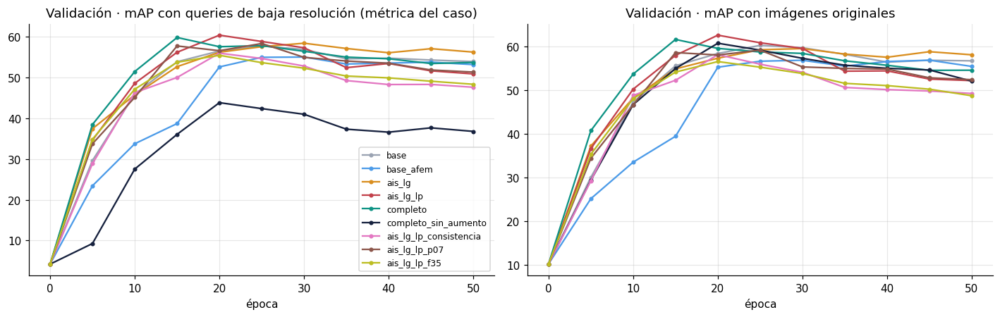

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for n in EXPS:
    v = R[n]["val"]
    ax[0].plot([x["epoch"] for x in v], [x["baja_res"]["mAP"] for x in v], "o-", ms=3, color=COL[n], label=n)
    ax[1].plot([x["epoch"] for x in v], [x["normal"]["mAP"] for x in v], "o-", ms=3, color=COL[n], label=n)
ax[0].set_title("Validación · mAP con queries de baja resolución (métrica del caso)"); ax[1].set_title("Validación · mAP con imágenes originales")
for a in ax: a.set_xlabel("época")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "validacion_curvas.png"), dpi=130); plt.show()

In [12]:
filas = []
for n in EXPS:
    best = max(R[n]["val"], key=lambda x: x["baja_res"]["mAP"])
    o, b = best["normal"], best["baja_res"]
    filas.append({"Configuración": n, "mejor época": best["epoch"],
                  "mAP baja": b["mAP"], "R-1 baja": b["Rank-1"], "R-5 baja": b["Rank-5"], "R-10 baja": b["Rank-10"],
                  "mAP orig.": o["mAP"], "R-1 orig.": o["Rank-1"], "Caída mAP (pts)": o["mAP"] - b["mAP"]})
tabla_val = pd.DataFrame(filas).set_index("Configuración").round(2)
tabla_val.to_csv(os.path.join("presentacion", "resultados", "tabla_validacion.csv"))
tabla_val

,mejor época,mAP baja,R-1 baja,R-5 baja,R-10 baja,mAP orig.,R-1 orig.,Caída mAP (pts)
Configuración,,,,,,,,
base,25,57.68,66.0,80.0,86.0,60.34,71.0,2.67
base_afem,30,54.94,73.0,78.0,82.0,56.92,73.0,1.98
ais_lg,30,58.34,70.0,80.0,82.0,59.60,73.0,1.26
ais_lg_lp,20,60.31,73.0,81.0,87.0,62.67,78.0,2.37
completo,15,59.74,73.0,83.0,89.0,61.69,73.0,1.96
completo_sin_aumento,20,43.78,56.0,68.0,77.0,60.83,73.0,17.05
ais_lg_lp_consistencia,20,55.90,69.0,83.0,89.0,58.21,69.0,2.31
ais_lg_lp_p07,25,58.26,70.0,81.0,87.0,59.23,75.0,0.97
ais_lg_lp_f35,20,55.37,67.0,76.0,81.0,56.62,68.0,1.24


- **Regla de selección:** mayor mAP de validación con queries de baja resolución, en la mejor época de cada configuración.
- **Lo que muestran las curvas:**
  - Sin aumento de resolución, la curva de baja resolución queda ~15 puntos por debajo.
  - Todas alcanzan su máximo entre las épocas 15 y 30, y después bajan levemente: la red empieza a memorizar los errores de las pseudo-etiquetas.

In [13]:
op = next(o for o in SEL["opciones_test"] if o["flip_tta"] == SEL["opcion_elegida"]["flip_tta"])["val"]
print(f"Configuración elegida: {SEL['configuracion']} ({run_caso.DESCRIPCION[SEL['configuracion']]})")
print(f"Época: {SEL['epocas']} · flip TTA: {SEL['opcion_elegida']['flip_tta']} "
      f"(sin flip: {[o for o in SEL['opciones_test'] if not o['flip_tta']][0]['val']['baja_res']['mAP']:.2f}, con flip: "
      f"{[o for o in SEL['opciones_test'] if o['flip_tta']][0]['val']['baja_res']['mAP']:.2f})")
metrica = pd.DataFrame([{"Condición": "queries de baja resolución (caso de uso)", **{k: op["baja_res"][k] for k in ("mAP", "Rank-1", "Rank-5", "Rank-10")}},
                        {"Condición": "imágenes originales", **{k: op["normal"][k] for k in ("mAP", "Rank-1", "Rank-5", "Rank-10")}}]).set_index("Condición").round(2)
print(f"Caída de mAP al reducir la resolución: {op['normal']['mAP'] - op['baja_res']['mAP']:.2f} puntos")
metrica

Configuración elegida: ais_lg_lp (base + AIS con Lg y Lp)
Época: 20 · flip TTA: True (sin flip: 60.31, con flip: 61.53)
Caída de mAP al reducir la resolución: 1.96 puntos


,mAP,Rank-1,Rank-5,Rank-10
Condición,,,,
queries de baja resolución (caso de uso),61.53,77.0,82.0,86.0
imágenes originales,63.48,78.0,84.0,87.0


**Métrica de validación del caso de uso:** la tabla anterior. Es la del modelo elegido (AIS con Lg y Lp, sin AFEM, época 20, flip TTA), entrenado solo con `training.h5`.

**Cautela:** con 100 queries de validación, diferencias de 1–2 puntos entre configuraciones pueden ser azar (la sección 7 lo cuantifica). En test, evaluado después de elegir, la configuración elegida también es la mejor de las nueve; la sección 7.3 muestra cuánto de esa ventaja depende de la semilla.

## 7. Aporte de cada componente (ablación)

### 7.1 Componentes del paper

**Cómo se mide.** Se comparan dos configuraciones **idénticas salvo por un componente**: misma semilla, mismos datos, mismo número de épocas y mismo criterio de época. La diferencia de mAP es el aporte del componente.

**¿Es real o es azar?** Para cada comparación se calcula un **intervalo de confianza del 95 % por bootstrap pareado**:
1. Cada query tiene su AP en ambos modelos.
2. Se remuestrean las queries con reposición 5 000 veces y se recalcula la diferencia media.
3. Si el intervalo no contiene el 0, la diferencia es estadísticamente clara para este conjunto de queries.

El intervalo **no** recoge la variación por entrenar con otra semilla (otro orden de batches, otros aumentos, otros clusters). Esa variación se mide aparte en la sección 7.3, repitiendo dos configuraciones con tres semillas.

In [14]:
apo = aportes.tabla(D)
apo.round(2).to_csv(os.path.join("presentacion", "resultados", "aportes.csv"), index=False)
es_mejora = apo["Con"].isin(MEJORAS)
vista = apo[(apo["Condición"] == "baja res.") & ~es_mejora][["Componente", "Partición", "mAP sin", "mAP con", "Aporte (pts)", "IC95 inf", "IC95 sup", "Conclusión"]]
vista.round(2).set_index(["Componente", "Partición"])

mAP sin    mAP con  Aporte (pts)   IC95 inf  IC95 sup      Conclusión
Componente                              Partición                                                                         
AFEM (sobre el base)                    val        59.820000  55.259998     -4.560000  -9.070000     -0.12         empeora
                                        test       36.060001  35.110001     -0.950000  -1.520000     -0.37         empeora
AFEM (sobre AIS Lg + Lp)                val        61.540001  60.160000     -1.380000  -5.380000      2.68  no concluyente
                                        test       40.450001  38.090000     -2.360000  -2.950000     -1.74         empeora
AIS con Lg (sobre el base)              val        59.820000  58.560001     -1.260000  -5.040000      2.47  no concluyente
                                        test       36.060001  38.930000      2.870000   2.280000      3.45          mejora
Lp (sobre AIS con Lg)                   val        58.560001  61.540001      2.990000  -0.610000      6.42  no concluyente
                                        test       38.930000  40.450001      1.510000   0.910000      2.14          mejora
AIS completo: Lg + Lp (sobre el base)   val        59.820000  61.540001      1.720000  -2.310000      5.96  no concluyente
                                        test       36.060001  40.450001      4.390000   3.740000      5.02          mejora
Aumento de resolución (método completo) val        44.810001  60.160000     15.350000  10.050000     20.74          mejora
                                        test       18.209999  38.090000     19.879999  19.049999     20.73          mejora

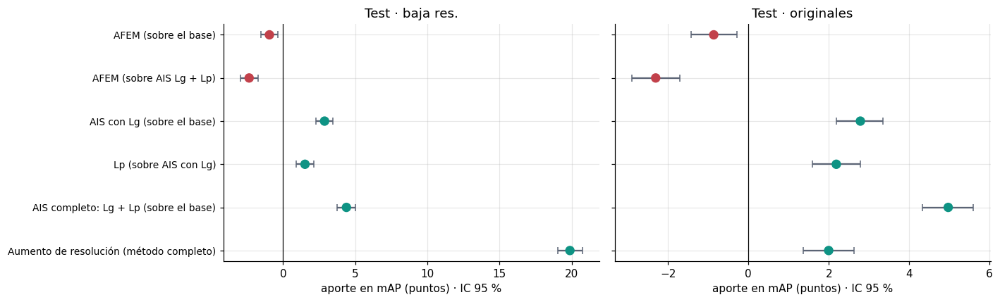

In [15]:
t = apo[(apo["Partición"] == "test") & ~es_mejora].copy()
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, cond in zip(axs, ("baja res.", "originales")):
    s = t[t["Condición"] == cond].reset_index(drop=True)
    y = np.arange(len(s))[::-1]
    col = ["#0E9384" if c == "mejora" else ("#C2414B" if c == "empeora" else "#9AA3B2") for c in s["Conclusión"]]
    ax.errorbar(s["Aporte (pts)"], y, xerr=[s["Aporte (pts)"] - s["IC95 inf"], s["IC95 sup"] - s["Aporte (pts)"]],
                fmt="none", ecolor="#5B6475", capsize=3)
    ax.scatter(s["Aporte (pts)"], y, c=col, s=60, zorder=3)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(y); ax.set_yticklabels(s["Componente"], fontsize=9)
    ax.set_xlabel("aporte en mAP (puntos) · IC 95 %"); ax.set_title(f"Test · {cond}")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "aportes_ic.png"), dpi=130); plt.show()

**Lectura (test, 3 368 queries):**

| Componente | Aporte en baja resolución | Interpretación |
|---|---|---|
| **Aumento de resolución** | **+19.9** [19.0, 20.7] | lo que hace funcionar al método en el caso de uso: sin él, el mAP con queries de baja resolución se reduce a la mitad |
| **AIS completo (Lg + Lp)** | **+4.4** [3.7, 5.0] | el aporte central del paper se reproduce |
| AIS con Lg | +2.9 [2.3, 3.5] | suplementar la etiqueta global con las franjas ayuda |
| Lp sobre Lg | +1.5 [0.9, 2.1] | entrenar las franjas, con la ponderación S, suma |
| **AFEM** sobre el base | **−1.0** [−1.5, −0.4] | no ayuda: empeora levemente |
| **AFEM** sobre AIS | **−2.4** [−3.0, −1.7] | tampoco suma cuando se combina con AIS |

**En validación** (100 queries) los intervalos son de ±4–5 puntos y casi nada es concluyente, salvo el aumento de resolución. Por eso la conclusión sobre AIS y AFEM se apoya en test, evaluado después de elegir. La sección 7.3 revisa estas cifras a la luz de la variación entre semillas.

### 7.2 Mejoras probadas para el caso de uso

Tres cambios sobre la configuración AIS con Lg y Lp. Ninguno modifica el método del paper (AIS, AFEM, pérdidas, clustering y backbone siguen igual) ni las reglas del enunciado: la gallery sigue en resolución original, se evalúa el mismo modelo en ambas condiciones, la elección se hace solo con validación y el test no se usa para ajustar nada.

| Configuración | Qué cambia | Idea |
|---|---|---|
| `ais_lg_lp_consistencia` | Cada imagen del batch se pasa **dos veces**: en resolución original y reducida (con el mismo recorte, flip y borrado). Se suma la pérdida `1 − cos(f_baja, f_original)`, sin propagar gradiente por la versión original (peso 1.0). Las pérdidas del paper usan una de las dos versiones al azar (p = 0.5). | Pedir explícitamente que la versión reducida de una persona caiga en el mismo punto que la original |
| `ais_lg_lp_p07` | El aumento de resolución se aplica con probabilidad 0.7 en vez de 0.5 | Ver más ejemplos parecidos a las queries del caso |
| `ais_lg_lp_f35` | El factor de reducción se sortea entre 3 y 5 en vez de 2 y 4 | Acercarse más a la reducción real de las queries (4×) y ver casos aún peores |

Las tres compiten con las demás configuraciones en la selección por validación (sección 6) y se comparan con `ais_lg_lp` con el mismo bootstrap pareado.

In [16]:
filas = []
for n in ["ais_lg_lp"] + MEJORAS:
    best = max(R[n]["val"], key=lambda x: x["baja_res"]["mAP"])
    t_ = R[n]["test_mejor_epoca"]
    filas.append({"Configuración": n, "mejor época": best["epoch"], "val mAP baja": best["baja_res"]["mAP"], "val mAP orig.": best["normal"]["mAP"],
                  "test mAP baja": t_["baja_res"]["mAP"], "test R-1 baja": t_["baja_res"]["Rank-1"], "test mAP orig.": t_["normal"]["mAP"],
                  "caída test (pts)": t_["normal"]["mAP"] - t_["baja_res"]["mAP"]})
display(pd.DataFrame(filas).set_index("Configuración").round(2))
apo[(apo["Condición"] == "baja res.") & es_mejora][["Componente", "Partición", "mAP sin", "mAP con", "Aporte (pts)", "IC95 inf", "IC95 sup", "Conclusión"]] \
    .round(2).set_index(["Componente", "Partición"])

,mejor época,val mAP baja,val mAP orig.,test mAP baja,test R-1 baja,test mAP orig.,caída test (pts)
Configuración,,,,,,,
ais_lg_lp,20,60.31,62.67,40.45,64.01,43.64,3.19
ais_lg_lp_consistencia,20,55.90,58.21,35.22,58.19,37.77,2.55
ais_lg_lp_p07,25,58.26,59.23,39.31,62.38,41.27,1.96
ais_lg_lp_f35,20,55.37,56.62,37.12,60.33,38.69,1.57


mAP sin    mAP con  Aporte (pts)  IC95 inf  IC95 sup      Conclusión
Componente                                         Partición                                                                        
Consistencia entre resoluciones (sobre AIS Lg +... val        61.540001  57.430000         -4.12     -7.78     -0.37         empeora
                                                   test       40.450001  35.220001         -5.22     -5.83     -4.60         empeora
Aumento con p = 0.7 en vez de 0.5                  val        61.540001  58.779999         -2.77     -6.22      0.80  no concluyente
                                                   test       40.450001  39.299999         -1.15     -1.81     -0.48         empeora
Reducción 3–5× en vez de 2–4×                      val        61.540001  55.990002         -5.56     -9.88     -1.23         empeora
                                                   test       40.450001  37.119999         -3.32     -3.95     -2.70         empeora

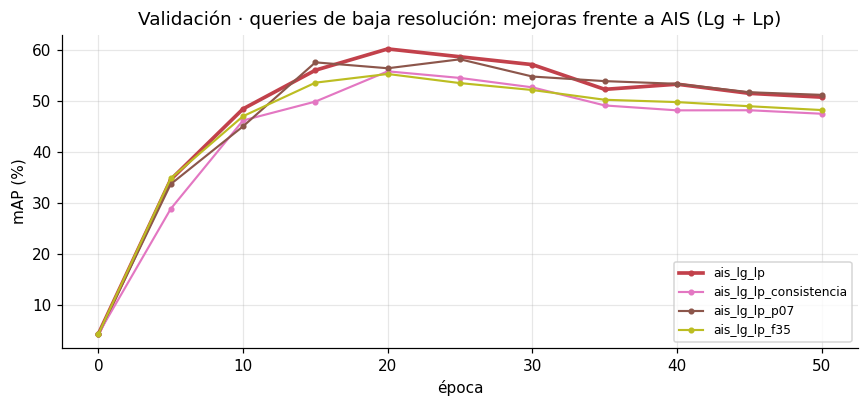

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for n in ["ais_lg_lp"] + MEJORAS:
    v = R[n]["val"]
    ax.plot([x["epoch"] for x in v], [x["baja_res"]["mAP"] for x in v], "o-", ms=3, color=COL[n], label=n, lw=2.4 if n == "ais_lg_lp" else 1.4)
ax.set_xlabel("época"); ax.set_ylabel("mAP (%)"); ax.set_title("Validación · queries de baja resolución: mejoras frente a AIS (Lg + Lp)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "mejoras_validacion.png"), dpi=130); plt.show()

**Lectura (test, queries de baja resolución):** ninguna de las tres mejoras supera a AIS con Lg y Lp, y la selección por validación no cambió.

| Mejora | Validación | Test | Aporte en test [IC 95 %] | ¿Supera la variación entre semillas (±2.3)? | Conclusión |
|---|---|---|---|---|---|
| Consistencia entre resoluciones | 55.9 | 35.2 | **−5.2** [−5.8, −4.6] | sí: queda por debajo de las tres semillas de `ais_lg_lp` (36.4–40.4) | **empeora** |
| Reducción 3–5× | 55.4 | 37.1 | −3.3 [−3.9, −2.7] | no del todo: está dentro del rango de semillas | probablemente empeora |
| Aumento con p = 0.7 | 58.3 | 39.3 | −1.1 [−1.8, −0.5] | no: está por encima de la media de semillas (37.8) | **no concluyente** |

El intervalo del bootstrap dice "empeora" en las tres, pero solo mide la variación por queries. Comparado con la variación entre semillas (sección 7.3), solo la consistencia queda claramente por debajo.

**Por qué la consistencia empeora** (hipótesis coherente con los datos, no demostrada):
- Pide que la versión reducida caiga en el mismo punto que la original. La forma más fácil de cumplirlo es **descartar los detalles finos** que la reducción borra (estampados, rostro, bordes), y esos detalles son justamente los que distinguen a personas parecidas.
- Prueba de ello: **también empeora con imágenes originales** (37.8 frente a 43.6), donde no hay nada que "rescatar".
- Con peso 1.0 compite con las pérdidas del paper (la total ronda 1.5–2), así que su efecto es fuerte.

**Por qué 3–5× no ayuda:** las queries del caso están reducidas exactamente 4× (128 × 64 → 32 × 16). El rango 2–4× ya cubre ese caso e incluye ejemplos más suaves; 3–5× agrega reducciones peores que las reales, que entrenan con imágenes con menos información de la necesaria.

**Por qué p = 0.7 no se distingue:** más imágenes reducidas en el entrenamiento hacen que el modelo vea menos imágenes nítidas. Baja algo en originales (41.3 frente a 43.6) y queda igual en baja resolución dentro del ruido.

**Conclusión:** la configuración del aumento de resolución que ya usábamos (p = 0.5, 2–4×) es la adecuada, y una pérdida extra de consistencia es contraproducente en este método. Las tres pruebas se reportan, aunque no mejoren, porque **descartan alternativas razonables con evidencia**.

### 7.3 Variación entre semillas

Todo lo anterior compara **una corrida por configuración** (semilla 1). Una red entrenada con otra semilla ve los batches en otro orden, recibe otros aumentos y, como los clusters de DBSCAN dependen de la red, obtiene **otras pseudo-etiquetas** desde la primera época. En aprendizaje no supervisado esa diferencia se amplifica.

Para medirla se repitieron, con las semillas 2 y 3:
- la **configuración elegida** (`ais_lg_lp`),
- el **base** (`base`), para saber si el aporte de AIS se sostiene con otras semillas.

Cada réplica sigue el mismo protocolo: mejor época por validación y test con flip TTA. Las réplicas **no participan en la selección**; solo miden la variación.

Semillas      mAP por semilla  Media  Desv. estándar
Configuración Partición Condición                                                       
ais_lg_lp     val       baja res.          3  60.31, 56.93, 58.86  58.70            1.69
                        originales         3  62.67, 58.09, 60.56  60.44            2.29
              test      baja res.          3  40.45, 36.64, 36.39  37.83            2.27
                        originales         3  43.64, 39.26, 38.88  40.60            2.64
base          val       baja res.          3  57.68, 56.00, 51.98  55.22            2.93
                        originales         3  60.34, 56.97, 53.49  56.93            3.43
              test      baja res.          3  36.06, 33.89, 32.33  34.09            1.87
                        originales         3  38.68, 35.90, 34.51  36.36            2.12

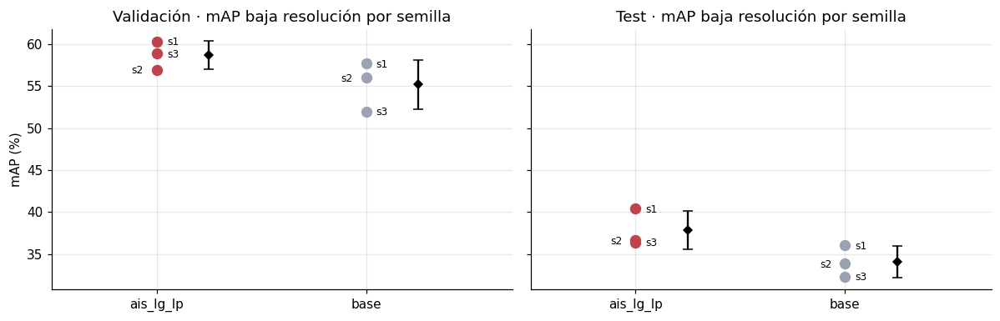

In [18]:
sem = aportes.semillas(R)
sem.round(2).to_csv(os.path.join("presentacion", "resultados", "semillas.csv"), index=False)
display(sem.round(2).set_index(["Configuración", "Partición", "Condición"]))
grupos = {b: [b] + sorted(k for k, v in R.items() if isinstance(v, dict) and v.get("replica_de") == b) for b in sem["Configuración"].unique()}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, (split, clave) in zip(ax, (("val", None), ("test", "test_mejor_epoca"))):
    for i, (b, nombres) in enumerate(grupos.items()):
        if split == "val":
            ys = [max(R[n]["val"], key=lambda x: x["baja_res"]["mAP"])["baja_res"]["mAP"] for n in nombres]
        else:
            ys = [R[n][clave]["baja_res"]["mAP"] for n in nombres if clave in R[n]]
        a.scatter([i] * len(ys), ys, s=60, color=COL[b], zorder=3)
        for j, (y_, n) in enumerate(zip(ys, nombres)):           # etiquetas alternadas a izquierda y derecha para que no se tapen
            a.annotate("s1" if n == b else "s" + n[-1], (i, y_), xytext=(8 if j % 2 == 0 else -20, -3), textcoords="offset points", fontsize=8)
        a.errorbar(i + 0.25, np.mean(ys), yerr=np.std(ys, ddof=1) if len(ys) > 1 else 0, fmt="D", color="k", capsize=4, ms=5)
    a.set_xticks(range(len(grupos))); a.set_xticklabels(list(grupos)); a.set_xlim(-0.5, len(grupos) - 0.3)
    a.set_title(f"{'Validación' if split == 'val' else 'Test'} · mAP baja resolución por semilla")
ax[0].set_ylabel("mAP (%)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "semillas.png"), dpi=130); plt.show()

**Lectura:**

| | Semilla 1 | Semilla 2 | Semilla 3 | Media ± desv. |
|---|---|---|---|---|
| `ais_lg_lp` · test, baja res. | 40.4 | 36.6 | 36.4 | **37.8 ± 2.3** |
| `base` · test, baja res. | 36.1 | 33.9 | 32.3 | **34.1 ± 1.9** |
| **Diferencia (AIS − base)** | +4.4 | +2.8 | +4.1 | **+3.7 ± 0.9** |

1. **La variación entre semillas es grande: ±2 puntos de mAP en test.** Es mayor que el intervalo del bootstrap (±0.6) porque en aprendizaje no supervisado una pequeña diferencia en las primeras épocas cambia los clusters, y los clusters son las etiquetas con las que se entrena todo lo demás.
2. **El aporte de AIS se sostiene:** con **las tres semillas** AIS supera al base, y la ventaja media es **+3.7 puntos** (frente a +4.4 con la semilla 1). La conclusión principal del paper se reproduce de forma robusta.
3. **La semilla 1 de `ais_lg_lp` fue una corrida favorable** (40.4 frente a una media de 37.8). Es el efecto esperado de elegir la mejor de nueve configuraciones por validación: la que gana suele ser buena **y** afortunada. El valor de test del modelo elegido es honesto (se midió después de elegir), pero la expectativa de otra corrida con la misma receta es ~38 en `training.h5` solo.
4. **Consecuencias para las demás comparaciones:** aportes de 1–2 puntos medidos con una sola semilla (Lp sobre Lg, AFEM sobre el base, p = 0.7) **no se distinguen** de la variación entre entrenamientos. Las diferencias grandes sí son firmes: el aumento de resolución (+19.9), AIS (+3.7 de media) y la consistencia (−5.2).
5. **En validación la variación es aún mayor** (desv. 1.7–2.9 con 100 queries), lo que confirma que la validación sirve para descartar opciones claramente peores, no para ordenar opciones parecidas.

## 8. Qué hacen AFEM y AIS por dentro

### 8.1 AFEM: ¿qué conserva y qué pasa si se apaga?

Medimos sobre la red `completo` ya entrenada (con AFEM sin weight decay):
1. **Qué fracción de canales** pasa la compuerta (máscara 1) en cada posición del mapa 24 × 8, promediada sobre las queries de test.
2. **Prueba de apagado:** se evalúa la misma red con AFEM reemplazado por la identidad.

In [19]:
af = DIAG["afem"]
print(f"γ medio = {af['gamma_media']:.3f} · β medio = {af['beta_media']:.3f} · fracción de activaciones con máscara 1 = {af['fraccion_mascara_1']:.1%}")
pd.DataFrame([{"Partición": s, "Condición": m, "mAP con AFEM": af[f"apagado_{s}"][m]["con_afem"], "mAP con AFEM apagado": af[f"apagado_{s}"][m]["sin_afem"]}
              for s in ("val", "test") for m in ("normal", "baja_res")]).round(3)

γ medio = 1.019 · β medio = -0.080 · fracción de activaciones con máscara 1 = 1.2%


,Partición,Condición,mAP con AFEM,mAP con AFEM apagado
0,val,normal,61.796,61.777
1,val,baja_res,60.161,60.159
2,test,normal,41.335,41.335
3,test,baja_res,38.091,38.090


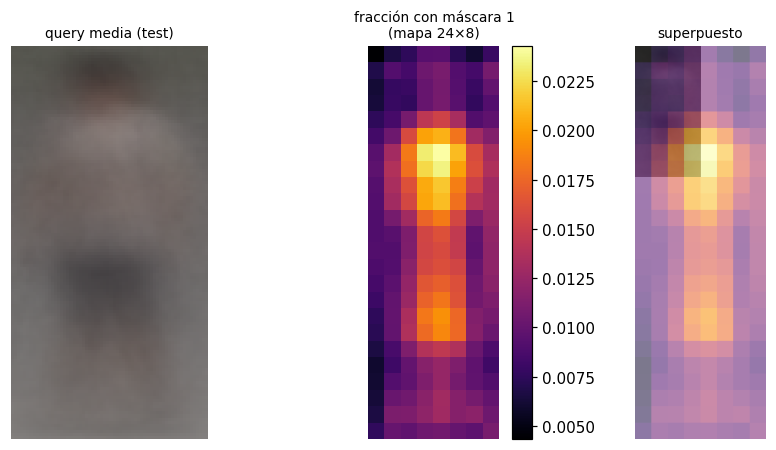

In [20]:
km = D["afem_keep_map"]
img_media = (q["images"][:500].float().mean(0) / 255).permute(1, 2, 0).numpy()
fig, ax = plt.subplots(1, 3, figsize=(8, 4.2))
ax[0].imshow(img_media); ax[0].set_title("query media (test)", fontsize=9)
im = ax[1].imshow(km, cmap="inferno"); ax[1].set_title("fracción con máscara 1\n(mapa 24×8)", fontsize=9); plt.colorbar(im, ax=ax[1], fraction=0.08)
ax[2].imshow(img_media); ax[2].imshow(np.kron(km, np.ones((16, 16))), cmap="inferno", alpha=0.55); ax[2].set_title("superpuesto", fontsize=9)
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "afem_mascara.png"), dpi=130); plt.show()

**Por qué AFEM no aporta.** Viene de la propia formulación del paper (ec. 2–4):
- `W_γ = softmax(γ)` reparte un peso total de 1 entre **2048 canales**: cada peso vale ≈ 1/2048 ≈ 0.0005.
- Entonces `W_γ · GN(X)` es un número minúsculo y la sigmoide da prácticamente **0.5 para cualquier activación**.
- Que pase el umbral (r > 0.5) depende solo del signo de GN(X); durante el entrenamiento la red movió β a negativo (≈ −0.08), y la compuerta quedó cerrada para casi todo: **solo ~1 % de las activaciones conserva su valor** y el resto se multiplica por ≈ 0.5.
- Multiplicar todo el mapa por la misma constante no cambia nada, porque después el vector se normaliza (L2) y se compara por coseno. Eso explica que **apagar AFEM no cambie el mAP** (diferencias de milésimas).
- El efecto negativo que se ve en la ablación (−1 a −2 puntos) se produce **durante el entrenamiento**: en las primeras épocas la compuerta sí estaba abierta para una parte de las activaciones y cambió los clusters iniciales y la trayectoria del aprendizaje. Las configuraciones con AFEM tienen una sola corrida y la variación entre semillas es de ±2 puntos (sección 7.3), así que esa diferencia puede deberse en parte al azar del entrenamiento; lo firme es que AFEM no ayuda.

**Lo que muestra el mapa:** las pocas activaciones que pasan la compuerta se concentran en el **centro del cuerpo** (torso y piernas), no en los bordes ni en el fondo. La idea de AFEM, realzar a la persona, apunta en la dirección correcta, pero abarca solo ~1–2 % de las activaciones, demasiado poco para cambiar el vector final.

**Conclusión sobre AFEM:** tal como está formulado (softmax sobre todos los canales), su compuerta queda casi cerrada y no logra separar persona y fondo con fuerza suficiente en estos datos. Por eso la validación lo descartó. Una variante con pesos por canal sin softmax (por ejemplo `γ_i / Σγ` con γ positivos, o una sigmoide sin normalizar) podría recuperar su función; queda como trabajo futuro.

### 8.2 AIS: ¿qué franjas considera confiables?

Puntaje S de cada imagen de `training.h5` con el modelo elegido (las tres franjas: cabeza y hombros, torso, piernas):

Modelo: ais_lg_lp · S medio por franja: cabeza 0.568 · torso 0.654 · piernas 0.515


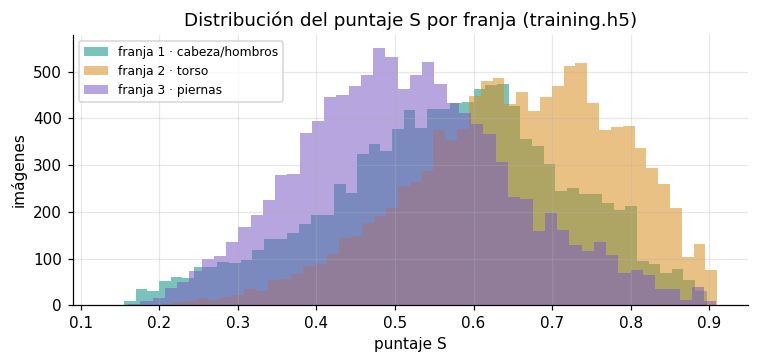

In [21]:
S = D["ais_S_train"]
print(f"Modelo: {DIAG['ais']['modelo']} · S medio por franja: cabeza {S[:, 0].mean():.3f} · torso {S[:, 1].mean():.3f} · piernas {S[:, 2].mean():.3f}")
fig, ax = plt.subplots(figsize=(7, 3.4))
for n, (et, c) in enumerate((("franja 1 · cabeza/hombros", "#0E9384"), ("franja 2 · torso", "#D98E1F"), ("franja 3 · piernas", "#7A5CC4"))):
    ax.hist(S[:, n], bins=50, alpha=0.55, color=c, label=et)
ax.set_xlabel("puntaje S"); ax.set_ylabel("imágenes"); ax.legend(fontsize=8); ax.set_title("Distribución del puntaje S por franja (training.h5)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "ais_S_hist.png"), dpi=130); plt.show()

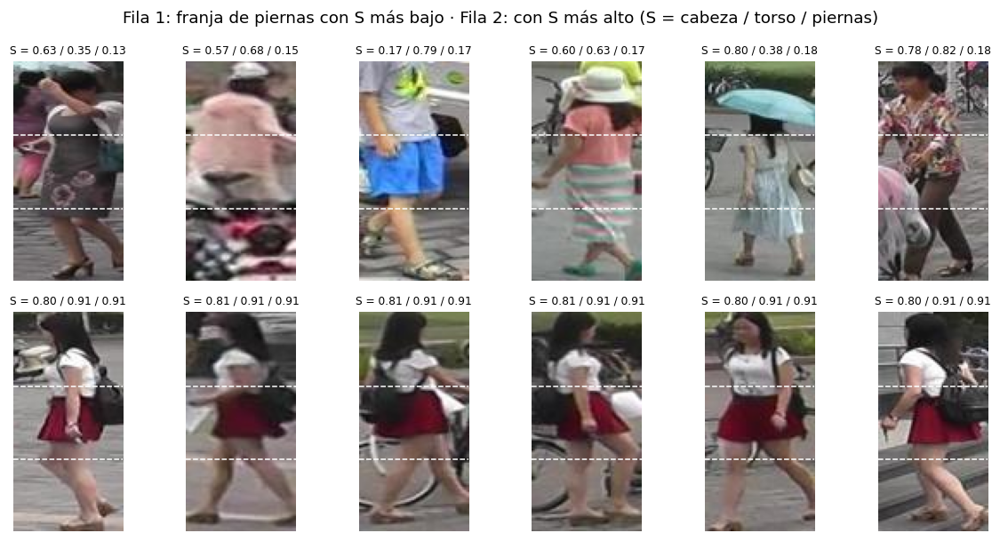

In [22]:
orden_s = np.argsort(S[:, 2])
casos_s = [("S piernas más bajo", i) for i in orden_s[:6]] + [("S piernas más alto", i) for i in orden_s[-6:]]
fig, ax = plt.subplots(2, 6, figsize=(11, 5.6))
for k, (et, i) in enumerate(casos_s):
    a = ax[k // 6, k % 6]
    a.imshow(train["images"][i].permute(1, 2, 0).numpy())
    for yline in (128 / 3, 2 * 128 / 3):
        a.axhline(yline, color="white", lw=1, ls="--")
    a.set_title(f"S = {S[i, 0]:.2f} / {S[i, 1]:.2f} / {S[i, 2]:.2f}", fontsize=8); a.axis("off")
ax[0, 0].set_ylabel("S piernas bajo"); ax[1, 0].set_ylabel("S piernas alto")
plt.suptitle("Fila 1: franja de piernas con S más bajo · Fila 2: con S más alto (S = cabeza / torso / piernas)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "ais_S_ejemplos.png"), dpi=130); plt.show()

**Lectura:**
- **El torso es la franja más confiable** (S medio 0.65) y **las piernas la menos confiable** (0.52), con la cabeza en medio (0.57).
- **Fila 1 (S de piernas más bajo, 0.13–0.18):** son justo los casos para los que se diseñó AIS. La parte baja está tapada por un paraguas o una bicicleta, se mezcla con otra persona u objeto (la cartera rosada en primer plano) o está mal recortada. Sus vecinos según las piernas no coinciden con sus vecinos según el cuerpo entero, así que AIS les baja el peso: en Lp esas franjas se empujan hacia "no estoy seguro" (distribución uniforme) en lugar de aprender una identidad equivocada, y en Lg aportan menos a la etiqueta suave.
- **Fila 2 (S de piernas más alto, 0.91):** imágenes de una misma persona con una falda roja muy distintiva; sus piernas recuperan a las mismas imágenes que el cuerpo entero, así que la franja es confiable y AIS la usa.

Así, **AIS funciona como un detector automático de franjas poco fiables (oclusiones, fondo, recortes)**, sin ninguna etiqueta. Eso explica su aporte en la ablación (+4.4 puntos de mAP en test).

## 9. Predicción en test y métricas finales

Dos modelos con la configuración elegida (AIS con Lg y Lp, sin AFEM, con aumento de resolución, flip TTA):
- **`ais_lg_lp`**: entrenado solo con `training.h5`, en su mejor época (20). Es el modelo cuya métrica de validación se reporta en la sección 6.
- **`final`**: la misma configuración, 20 épocas, entrenada con `training.h5` + las imágenes de validación **sin etiquetas** (atributo `final_training`).

Ambas condiciones se evalúan con el mismo modelo, vectores L2, similitud coseno y gallery original.

In [23]:
filas = []
for n, t_ in ((SEL["configuracion"], R[SEL["configuracion"]]["test_mejor_epoca"]), ("final", R["final"]["test"])):
    o, b = t_["normal"], t_["baja_res"]
    filas.append({"Modelo": n, "mAP orig.": o["mAP"], "R-1 orig.": o["Rank-1"], "R-5 orig.": o["Rank-5"], "R-10 orig.": o["Rank-10"],
                  "mAP baja": b["mAP"], "R-1 baja": b["Rank-1"], "R-5 baja": b["Rank-5"], "R-10 baja": b["Rank-10"],
                  "Caída mAP (pts)": o["mAP"] - b["mAP"], "Caída mAP (%)": 100 * (1 - b["mAP"] / o["mAP"])})
tabla_test = pd.DataFrame(filas).set_index("Modelo").round(2)
tabla_test.to_csv(os.path.join("presentacion", "resultados", "tabla_test.csv"))
tabla_test

,mAP orig.,R-1 orig.,R-5 orig.,R-10 orig.,mAP baja,R-1 baja,R-5 baja,R-10 baja,Caída mAP (pts),Caída mAP (%)
Modelo,,,,,,,,,,
ais_lg_lp,43.64,68.38,78.44,81.59,40.45,64.01,75.3,78.92,3.19,7.31
final,50.82,72.06,82.45,85.78,48.05,69.21,80.2,83.70,2.77,5.45


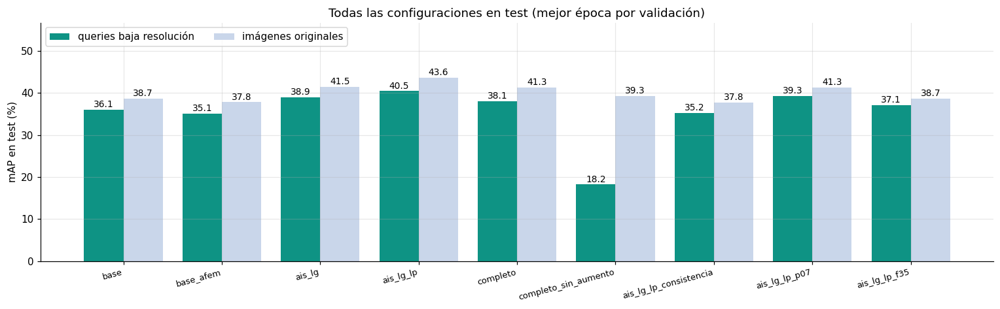

,test mAP baja,test R-1 baja,test mAP orig.,Caída mAP (pts)
Configuración,,,,
base,36.06,58.97,38.68,2.62
base_afem,35.11,57.57,37.81,2.70
ais_lg,38.94,61.64,41.46,2.52
ais_lg_lp,40.45,64.01,43.64,3.19
completo,38.09,60.99,41.34,3.25
completo_sin_aumento,18.21,28.15,39.33,21.12
ais_lg_lp_consistencia,35.22,58.19,37.77,2.55
ais_lg_lp_p07,39.31,62.38,41.27,1.96
ais_lg_lp_f35,37.12,60.33,38.69,1.57


In [24]:
filas = []
for n in EXPS:
    t_ = R[n]["test_mejor_epoca"]
    filas.append({"Configuración": n, "test mAP baja": t_["baja_res"]["mAP"], "test R-1 baja": t_["baja_res"]["Rank-1"],
                  "test mAP orig.": t_["normal"]["mAP"], "Caída mAP (pts)": t_["normal"]["mAP"] - t_["baja_res"]["mAP"]})
abl = pd.DataFrame(filas).set_index("Configuración").round(2)
abl.to_csv(os.path.join("presentacion", "resultados", "tabla_ablacion.csv"))
fig, ax = plt.subplots(figsize=(14, 4.4))
x = np.arange(len(abl))
ax.bar(x - 0.2, abl["test mAP baja"], 0.4, label="queries baja resolución", color="#0E9384")
ax.bar(x + 0.2, abl["test mAP orig."], 0.4, label="imágenes originales", color="#C9D6EA")
for i, (a, b_) in enumerate(zip(abl["test mAP baja"], abl["test mAP orig."])):
    ax.text(i - 0.2, a + 0.6, f"{a:.1f}", ha="center", fontsize=9); ax.text(i + 0.2, b_ + 0.6, f"{b_:.1f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(abl.index, fontsize=8.5, rotation=15, ha="right"); ax.set_ylabel("mAP en test (%)")
ax.set_ylim(0, 1.3 * abl["test mAP orig."].max()); ax.legend(loc="upper left", ncol=2)
ax.set_title("Todas las configuraciones en test (mejor época por validación)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "ablacion.png"), dpi=130); plt.show()
abl

## 10. Aciertos y fallos (modelo `final`)

Cinco aciertos y cinco fallos por condición. Para cada query: la imagen de consulta (en baja resolución, la de 32 × 16) y su top-10 de la gallery: **verde = misma persona**, rojo = otra. La tabla indica la posición del primer acierto, si el top-1 es de la misma cámara que la query y si es un distractor (ID 0).

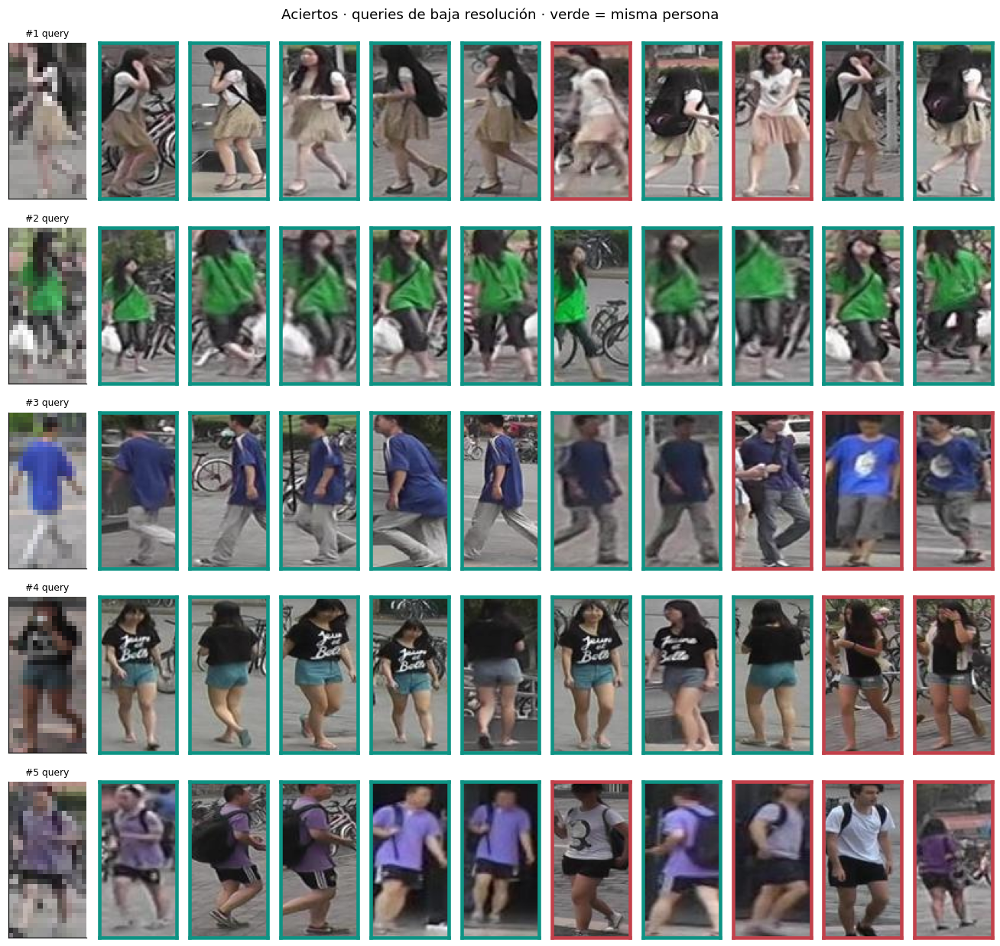

,query image_id,ID query,cámara query,ID top-1,cámara top-1,top-1 misma cámara,top-1 distractor,primer acierto en
#,,,,,,,,
1,1ef3f0a3ff0e470eb818124b,1125,5,1125,1,False,False,1
2,fd2830e0fae5ba22809e19b0,295,3,295,5,False,False,1
3,432f98abed733ca6fc4e4747,187,6,187,5,False,False,1
4,07f285a2ac75e9dbd93e34d1,1161,1,1161,2,False,False,1
5,1798b7c654662f932c51d2dc,789,3,789,5,False,False,1


In [25]:
q, g = test["query"], test["gallery"]
gid = {k: i for i, k in enumerate(g["ids"])}

def primer_acierto(row, qi):
    for k in range(10):
        if g["pids"][gid[row[f"top{k + 1}"]]] == q["pids"][qi]:
            return k + 1
    return None

def casos(cond, tipo, n=5, seed=11):
    pf = pd.read_csv(os.path.join(rc.PRED_DIR, f"final_{cond}.csv"))
    pool = np.flatnonzero(pf.top1_correcto == (1 if tipo == "acierto" else 0))
    sel_ = np.random.RandomState(seed).choice(pool, n, replace=False)
    fig, ax = plt.subplots(n, 11, figsize=(12, 2.3 * n))
    info = []
    for r, qi in enumerate(sel_):
        row = pf.iloc[qi]
        img = q["images_low"][qi] if cond == "baja_res" else q["images"][qi]
        ax[r, 0].imshow(img.permute(1, 2, 0).numpy()); ax[r, 0].set_title(f"#{r + 1} query", fontsize=8)
        for k in range(10):
            j = gid[row[f"top{k + 1}"]]
            ax[r, k + 1].imshow(g["images"][j].permute(1, 2, 0).numpy())
            for s in ax[r, k + 1].spines.values():
                s.set_visible(True); s.set_linewidth(3); s.set_color("#0E9384" if g["pids"][j] == q["pids"][qi] else "#C2414B")
        for a in ax[r]: a.set_xticks([]); a.set_yticks([]); a.grid(False)
        j1 = gid[row["top1"]]
        info.append({"#": r + 1, "query image_id": q["ids"][qi], "ID query": int(q["pids"][qi]), "cámara query": int(q["cams"][qi]) + 1,
                     "ID top-1": int(g["pids"][j1]), "cámara top-1": int(g["cams"][j1]) + 1,
                     "top-1 misma cámara": bool(g["cams"][j1] == q["cams"][qi]), "top-1 distractor": bool(g["pids"][j1] == 0),
                     "primer acierto en": primer_acierto(row, qi)})
    et = "queries de baja resolución" if cond == "baja_res" else "imágenes originales"
    plt.suptitle(f"{tipo.capitalize()}s · {et} · verde = misma persona"); plt.tight_layout()
    plt.savefig(os.path.join(FIG, f"{tipo}s_{cond}.png"), dpi=130); plt.show()
    return pd.DataFrame(info).set_index("#")

casos("baja_res", "acierto")

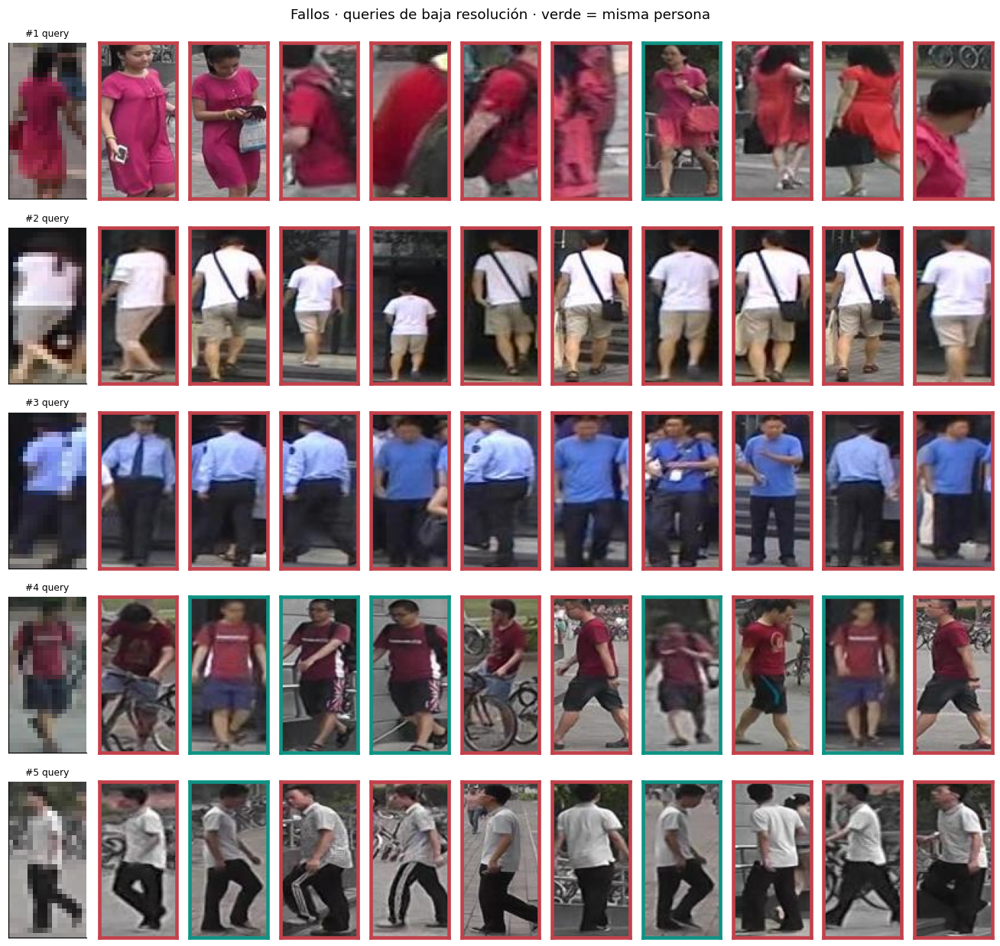

,query image_id,ID query,cámara query,ID top-1,cámara top-1,top-1 misma cámara,top-1 distractor,primer acierto en
#,,,,,,,,
1,c03d1450f3925f6225d5a596,1205,1,1083,3,False,False,7.0
2,ddd7ec7d540c71029bcdf34e,1413,6,1053,6,True,False,NaN
3,764712e8fd590c6591c2603e,728,6,731,6,True,False,NaN
4,f7de2ceb08eeb79bc3338576,909,2,0,4,False,True,2.0
5,97af0b1396ccc735f4ca0c5d,1233,5,1082,5,True,False,2.0


In [26]:
casos("baja_res", "fallo")

**Aciertos (baja resolución):** en los cinco casos la persona correcta es el top-1 y aparece desde **otra cámara** ("top-1 misma cámara" = False). El modelo la reconoce por la combinación de colores y la silueta, que sobreviven a la reducción a 32 × 16, pese al cambio de punto de vista y de fondo.

**Fallos (baja resolución), uno por uno:**
1. **Vestido magenta (ID 1205).** En baja resolución la query es casi solo "una mancha magenta". La gallery tiene varias personas con ropa magenta o roja, incluso recortes muy cercanos de un torso rojo. El color domina la representación y la persona correcta aparece recién en la posición 7.
2. **Polera blanca y short beige, de espaldas, en la cámara 6 (ID 1413).** Es un atuendo muy común y la query tiene un objeto oscuro a la altura de la cadera que en 32 × 16 no se distingue. Todo el top-10 es otra gente vestida igual, y el top-1 es de la **misma cámara** (misma puerta oscura y misma luz).
3. **Camisa celeste y pantalón oscuro (ID 728).** En la cámara 6 hay **guardias con uniforme celeste**: personas distintas con ropa idéntica. Sin rostro ni detalles, el modelo no puede separarlas; ninguna del top-10 es correcta.
4. **Polera granate (ID 909).** Es un fallo cercano: el top-1 es un **distractor** (ID 0, una detección con bicicleta) y la persona correcta está en las posiciones 2, 3, 4, 7 y 9.
5. **Camisa blanca y pantalón negro (ID 1233).** Otro atuendo frecuente; el top-1 es otra persona de la **misma cámara** y la correcta aparece en la posición 2 (fallo cercano).

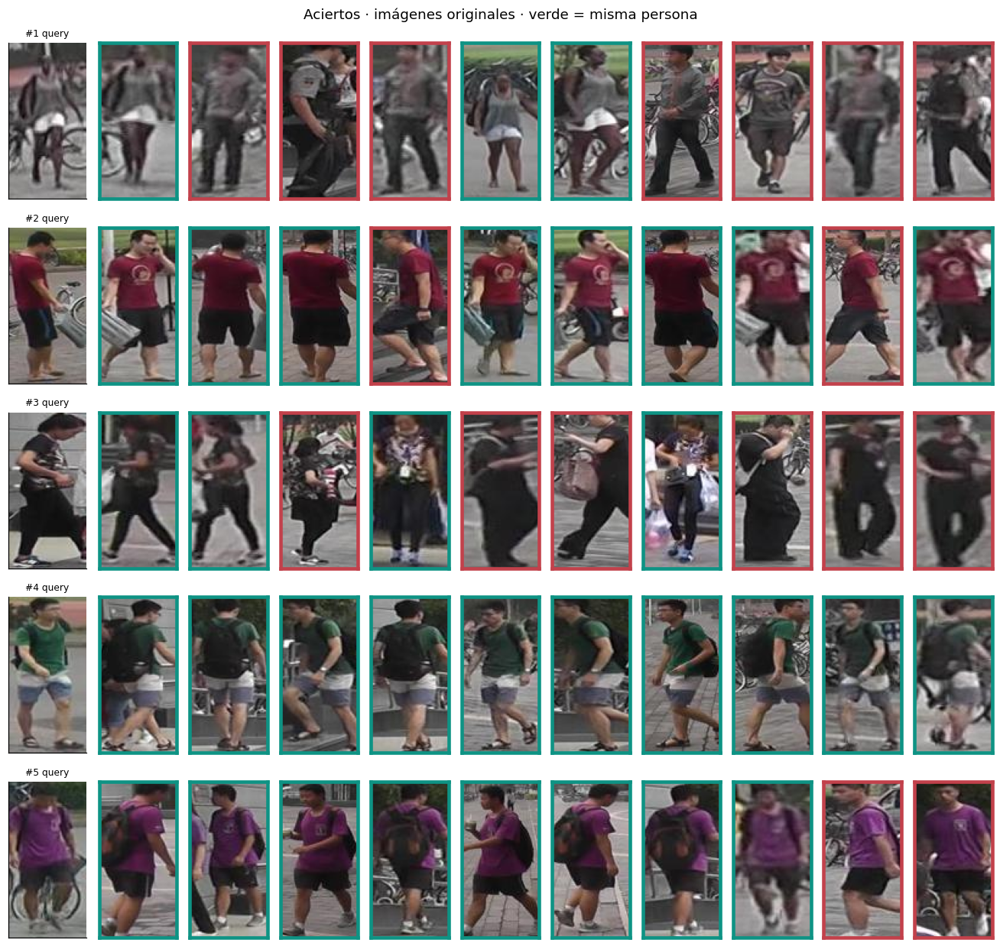

,query image_id,ID query,cámara query,ID top-1,cámara top-1,top-1 misma cámara,top-1 distractor,primer acierto en
#,,,,,,,,
1,b563e4f24e8f0786a38c53da,72,5,72,3,False,False,1
2,863101a200961e1d618da8ac,1270,4,1270,5,False,False,1
3,20c2cabfc717a83630bb9218,1102,3,1102,1,False,False,1
4,91a286effeb0951806d4949a,462,2,462,3,False,False,1
5,2a75fb6bca7bd1183d0e5b8f,1084,2,1084,1,False,False,1


In [27]:
casos("normal", "acierto")

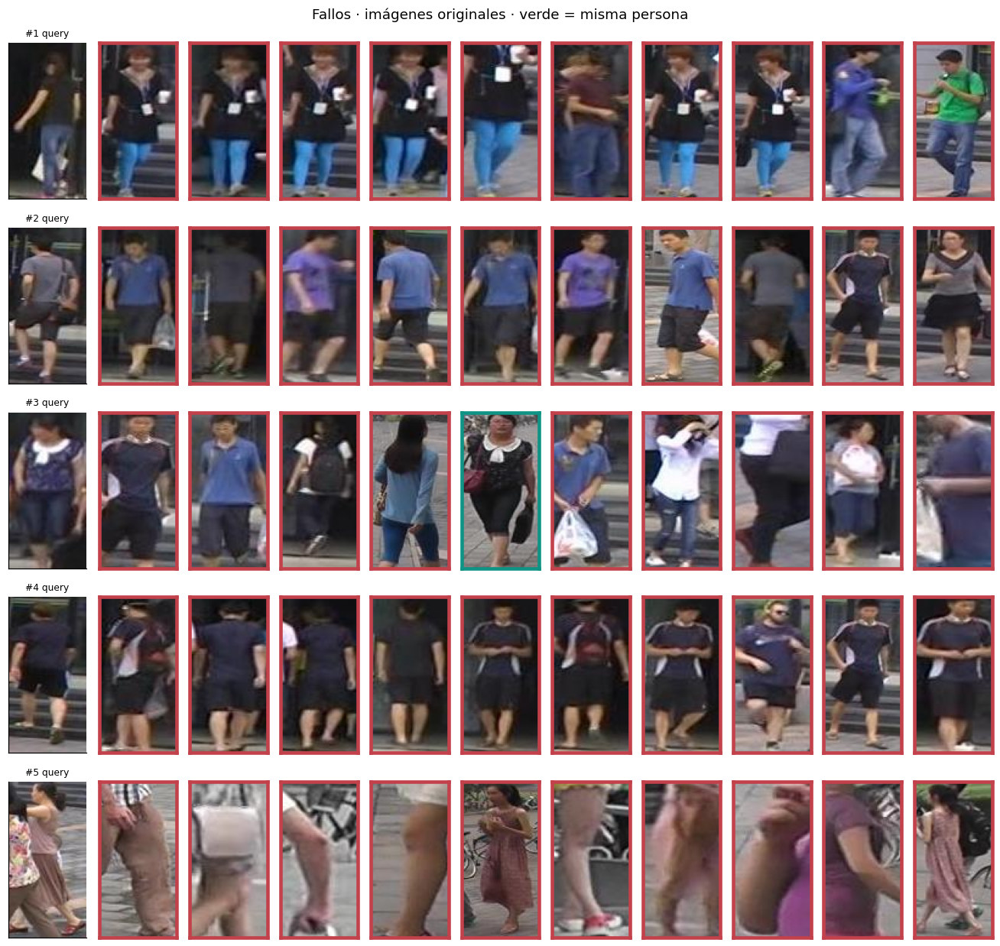

,query image_id,ID query,cámara query,ID top-1,cámara top-1,top-1 misma cámara,top-1 distractor,primer acierto en
#,,,,,,,,
1,9f9601187ec6ec3fb661872f,50,6,965,6,True,False,NaN
2,ab9a362aa8a5a0cc18391f92,1477,6,155,6,True,False,NaN
3,ab0db89364ea1aec0c5532aa,1015,6,618,6,True,False,5.0
4,b03a66e48f8eed2e8555b290,1472,6,618,6,True,False,NaN
5,3c0676f6dc32b75ac64cd9a4,270,6,0,5,False,True,NaN


In [28]:
casos("normal", "fallo")

**Aciertos (originales):** también se recuperan desde cámaras distintas. Con resolución completa el modelo puede usar además estampados, logos y accesorios.

**Fallos (originales), uno por uno.** Cuatro de los cinco son de la **cámara 6**, la puerta interior oscura:
1. **Mujer con polera negra y jeans (ID 50).** El top-10 está dominado por otra mujer de la misma cámara con polera negra, jeans celestes y credencial: misma luz, mismo fondo y ropa parecida. Ninguna imagen correcta llega al top-10.
2. **Polera gris y short oscuro, de espaldas (ID 1477).** El modelo devuelve hombres de la misma cámara con poleras azul o gris y short oscuro. De espaldas no hay rasgos que los distingan.
3. **Blusa estampada con cuello blanco (ID 1015).** El top-1 es una persona con polera azul marino de la misma cámara. La persona correcta aparece en la posición 5, captada en exterior con otra iluminación: **pesa más la cámara que la identidad**.
4. **Ropa azul marino de espaldas (ID 1472).** Todo el top-10 son personas de azul marino en la cámara 6. La combinación de "ropa oscura + cámara oscura" es la menos discriminativa.
5. **Recorte mal detectado (ID 270).** La query contiene a **dos personas** (una mujer de rosado y parte de otra), un error del detector de Market-1501. El modelo la compara con fragmentos (brazos, piernas, recortes parciales) y el top-1 es un **distractor**; ninguna correcta aparece.

## 11. Patrones de error en todo el test

In [29]:
filas = []
for cond in ("normal", "baja_res"):
    pf = pd.read_csv(os.path.join(rc.PRED_DIR, f"final_{cond}.csv"))
    err = pf[pf.top1_correcto == 0]
    j1 = np.array([gid[x] for x in err.top1])
    qi = err.index.values
    filas.append({"Condición": "originales" if cond == "normal" else "queries baja res.", "queries": len(pf),
                  "fallos top-1": len(err), "% fallos": 100 * len(err) / len(pf),
                  "fallos: top-1 de la misma cámara (%)": 100 * np.mean(g["cams"][j1] == q["cams"][qi]),
                  "fallos: top-1 distractor (%)": 100 * np.mean(g["pids"][j1] == 0),
                  "fallos: acierto dentro del top-10 (%)": 100 * np.mean([primer_acierto(pf.loc[i], i) is not None for i in qi])})
pf_b = pd.read_csv(os.path.join(rc.PRED_DIR, "final_baja_res.csv")); pf_n = pd.read_csv(os.path.join(rc.PRED_DIR, "final_normal.csv"))
print(f"Queries que se aciertan con la imagen original pero se fallan en baja resolución: {int(((pf_n.top1_correcto == 1) & (pf_b.top1_correcto == 0)).sum())}"
      f" · al revés: {int(((pf_n.top1_correcto == 0) & (pf_b.top1_correcto == 1)).sum())}")
pd.DataFrame(filas).set_index("Condición").round(1)

Queries que se aciertan con la imagen original pero se fallan en baja resolución: 175 · al revés: 79


,queries,fallos top-1,% fallos,fallos: top-1 de la misma cámara (%),fallos: top-1 distractor (%),fallos: acierto dentro del top-10 (%)
Condición,,,,,,
originales,3368,941,27.9,69.9,5.6,49.1
queries baja res.,3368,1037,30.8,66.1,5.9,47.1


**Patrones comunes:**
1. **Sesgo de cámara.** En ~66–70 % de los fallos, el top-1 equivocado es de la **misma cámara** que la query. Fondo, iluminación y punto de vista compartidos acercan las features aunque Lcam intenta reducirlo. La cámara 6 (puerta interior oscura) concentra muchos fallos.
2. **Ropa idéntica o colores dominantes.** Uniformes, poleras blancas, ropa oscura, magenta. Empeora en baja resolución, donde se pierden estampados y rostro: 175 queries se aciertan con la imagen original y se fallan en baja resolución, frente a 79 al revés.
3. **Errores del detector y distractores** (~6 % de los fallos): recortes con dos personas o fragmentos de cuerpo.
4. **Casi la mitad de los fallos son "cercanos":** la persona correcta sí está en el top-10. Son errores de **orden**, no de representación; en el uso real, un operador que mire 10 resultados la encontraría (Rank-10 = 83.7 % en baja resolución).

## 12. Predicciones para el conjunto de test

`presentacion/predicciones_test/` contiene, para el modelo validado (`ais_lg_lp`) y el modelo `final`, y para cada condición, un CSV con las 10 imágenes de la gallery más cercanas a cada query (por `image_id`), la identidad del top-1 y si es correcto.

In [30]:
for fn in sorted(os.listdir(rc.PRED_DIR)):
    df = pd.read_csv(os.path.join(rc.PRED_DIR, fn))
    print(f"{fn:28s} {len(df):5d} queries · top-1 correcto {df.top1_correcto.mean():.1%}")
pd.read_csv(os.path.join(rc.PRED_DIR, "final_baja_res.csv")).head(3)

ais_lg_lp_baja_res.csv        3368 queries · top-1 correcto 64.0%
ais_lg_lp_normal.csv          3368 queries · top-1 correcto 68.4%
final_baja_res.csv            3368 queries · top-1 correcto 69.2%
final_normal.csv              3368 queries · top-1 correcto 72.1%


,query_image_id,query_person_id,query_camera,top1,top2,top3,top4,top5,top6,top7,top8,top9,top10,top1_person_id,top1_correcto
0,0054dd683af106462344fd67,1191,3,4971684ab09ddd1dcbf7b042,98559d5ed9ee965e7937203a,7a3614780ad47784bb5f179a,f8292da9050e9fbd392bd443,0bbf9bd0233e5333c07f4587,5d628b818f2c1dea723045f3,6bc4c00f47207a813dafa90c,e4a0a837ea33785bc32c5a37,a77988aed03bd5d1fe82543c,a56d34c92a9a691fa00b8157,284,0
1,0055f4786285943da7de7580,873,5,1c2f32e81b15424aa8465b60,a96caa6cdae097281bff909d,250a4a5c06adb2271b0c0859,87d82d94a853626f030e5349,7c5d28786bca049ba5a9dc89,1d1fa25dd7f95778e86513a4,32baa91b271e1a459018d586,1a652dca68f1fe56045608ca,9288572d678c1076e41cbdf2,d1826048397249988bab0ce8,873,1
2,00604db23989a3f6f58ff1b4,360,4,cfdcbeb97f8b846bb616981e,48cea853ff6ff5e5984b8143,fe859a2cd2a8dc3ef8407180,f9f1fc5a7048ca3de9fdb64e,e547d4b22f718b014d29a4ee,3047804b4b5503a2248071ca,5936b9588a4197078bc35a65,49ff3cfef16144506fb06f5c,ac96389fd68c1f99d4fd2eef,871205f4cd3e707bec46cceb,725,0


## 13. Conclusiones, limitaciones y diferencias con el paper

**Respuesta al caso de uso**

| Métrica | Queries de baja resolución | Imágenes originales | Caída de mAP |
|---|---|---|---|
| **Validación** (modelo elegido, época 20) | mAP **61.5** · R-1 77.0 · R-5 82.0 · R-10 86.0 | mAP 63.5 · R-1 78.0 · R-5 84.0 · R-10 87.0 | 1.9 pts |
| **Test, modelo `final`** | mAP **48.1** · R-1 69.2 · R-5 80.2 · R-10 83.7 | mAP 50.8 · R-1 72.1 · R-5 82.5 · R-10 85.8 | **2.8 pts (−5 %)** |

**Conclusiones**
1. **El aumento de resolución es la adaptación clave para el caso:** aporta +19.9 puntos de mAP con queries de baja resolución y deja la caída por resolución en solo ~3 puntos.
2. **AIS, la propuesta central del paper, sí funciona:** Lg + Lp aportan +4.4 puntos con la semilla 1 (IC 95 % [3.7, 5.0]) y **+3.7 de media con tres semillas**, ganando al base con cada una. El puntaje S detecta franjas ocluidas sin etiquetas.
3. **AFEM no aporta en este caso** (−1.0 a −2.4 puntos): su compuerta, con softmax sobre 2048 canales, queda casi inactiva y apagarla no cambia el resultado. Por eso la validación lo descartó.
4. **Configuración elegida:** AIS con Lg y Lp, sin AFEM, con aumento de resolución, 20 épocas y flip TTA. Entrenar al final con train + imágenes de validación sin etiquetas sube el mAP de test de 40.4 a 48.1 (baja resolución).
5. **Mejoras probadas sin éxito:** la pérdida de consistencia entre resoluciones empeora (−5.2), y cambiar la probabilidad (0.7) o el rango (3–5×) del aumento no mejora. El aumento con p = 0.5 y 2–4× es el adecuado.
6. **Errores principales:** sesgo de cámara, ropa idéntica o colores dominantes, y errores del detector.

**Limitaciones**
- **Validación pequeña** (100 queries), con intervalos de ±4–5 puntos: elige bien entre opciones muy distintas, pero no entre opciones parecidas. La elección quedó confirmada en test.
- **Variación entre semillas de ±2 puntos de mAP en test**, medida con tres semillas para `base` y `ais_lg_lp`. Las demás configuraciones tienen una sola corrida, por lo que sus diferencias de 1–2 puntos no son concluyentes. La semilla 1 del modelo elegido fue favorable (40.4 frente a una media de 37.8).
- **Clustering** costoso (Jaccard O(N²)) y dependiente de la calidad de DBSCAN (~540–650 clusters para 651 personas).
- **Persisten errores** por sesgo de cámara y ropa idéntica, que ninguna de las piezas del paper resuelve.

**Diferencias con el paper**
- **Adaptaciones al caso:** aumento de resolución, AFEM sin weight decay, elección de la época y la configuración con validación, y entrenamiento final con train + validación sin etiquetas.
- **Detalles que el paper no especifica:** clasificador coseno (escala 20) reiniciado con centroides cada época, la feature comparada en la ec. 5 (la global) y los detalles de Lcam (proxies por época, momento 0.2, 50 negativos difíciles).
- **Entorno:** imágenes 128 × 64 re-escaladas a 384 × 128 como en el paper; 1 × RTX 5070 Ti con precisión bf16; aumentos en GPU.